# Computation or Weight Adaptation? Rethinking the role of plasticity in learning

Welcome to Our Notebook! 🚀  

To get started, you'll need to add your Hugging Face (HF) token to load the model. Follow these steps to securely add your token as a secret in your notebook:  

1. In the left sidebar, click on the **key icon**.  
2. Select **"Add new secret"**.  
3. Set the name to **`HF_token`**.  
4. Paste your Hugging Face access token as the value.  

If you don’t have an access token yet, you can generate one by following the instructions [here](https://huggingface.co/docs/hub/en/security-tokens).  


Below is a screenshot of how it should look like:


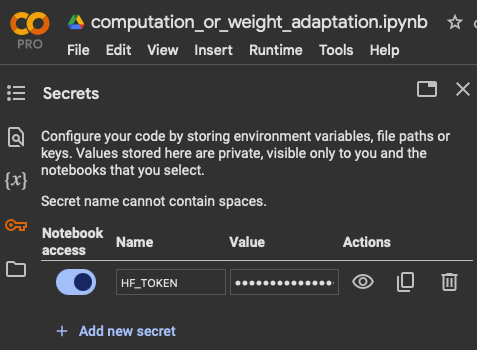

### Once your token is added, you're all set to run this notebook! 🚀

In [ ]:
!pip install --upgrade spacy
!python -m spacy download en_core_web_trf

## Import packages

In [ ]:
import json
import random
from tqdm import tqdm
import spacy
random.seed(42)

## Set run parameters

In [ ]:
RANDOM_WEIGHTS = False  # set to True if you want to use an untrained network
NO_REPETITIONS = False # set to False if you don't care about repetitions
model_name = 'mistral'  # paper's primary model (Mistral-7B-v0.3); use 'llama' for SI Fig. S3/S4A, 'gpt2' for SI Fig. S12
SEP_TOKEN = 'END'
iterations = 100
random_epochs = 85
learning_epochs = 340
END_NODE_ID = "END"
tokens_type = "words" # "words" "letters" "digits" "symbols" "all_nouns" "all_verbs"

In [ ]:
def extract_subset(word_list):
    """Extracts only noun words or verbs from a list using spaCy."""
    if tokens_type == "all_nouns":
      pos = "NOUN"
    elif tokens_type == "all_verbs":
      pos = "VERB"
    print(f"extracting {pos}")
    nlp = spacy.load("en_core_web_trf")  # Load spaCy's English model
    tokens = nlp(" ".join(word_list))
    reduced = [token.text for token in nlp(" ".join(word_list)) if token.pos_ == pos]
    return reduced

In [ ]:
if tokens_type == "letters":
  tokens_list = list('abcdefghijklmnopqrstuvwxyz')
elif tokens_type == "digits":
  tokens_list = list('123456789')
  SEP_TOKEN = "000"
elif tokens_type == "symbols":
  tokens_list = list('!@#$%^&*()_+-={}[]±§/\"\':;.?>,<~`´')
  SEP_TOKEN = "|"
  assert SEP_TOKEN not in tokens_list
elif tokens_type == "words" or tokens_type == "all_nouns" or tokens_type == "all_verbs":
  tokens_list = ['a', 'abandon', 'ability', 'able', 'abortion', 'about', 'above', 'abroad', 'absence', 'absolute', 'absolutely', 'absorb', 'abuse', 'academic', 'accept', 'access', 'accident', 'accompany', 'accomplish', 'according', 'account', 'accurate', 'accuse', 'achieve', 'achievement', 'acid', 'acknowledge', 'acquire', 'across', 'act', 'action', 'active', 'activist', 'activity', 'actor', 'actress', 'actual', 'actually', 'ad', 'adapt', 'add', 'addition', 'additional', 'address', 'adequate', 'adjust', 'adjustment', 'administration', 'administrator', 'admire', 'admission', 'admit', 'adolescent', 'adopt', 'adult', 'advance', 'advanced', 'advantage', 'adventure', 'advertising', 'advice', 'advise', 'adviser', 'advocate', 'affair', 'affect', 'afford', 'afraid', 'African', 'African-American', 'after', 'afternoon', 'again', 'against', 'age', 'agency', 'agenda', 'agent', 'aggressive', 'ago', 'agree', 'agreement', 'agricultural', 'ah', 'ahead', 'aid', 'aide', 'AIDS', 'aim', 'air', 'aircraft', 'airline', 'airport', 'album', 'alcohol', 'alive', 'all', 'alliance', 'allow', 'ally', 'almost', 'alone', 'along', 'already', 'also', 'alter', 'alternative', 'although', 'always', 'AM', 'amazing', 'American', 'among', 'amount', 'analysis', 'analyst', 'analyze', 'ancient', 'and', 'anger', 'angle', 'angry', 'animal', 'anniversary', 'announce', 'annual', 'another', 'answer', 'anticipate', 'anxiety', 'any', 'anybody', 'anymore', 'anyone', 'anything', 'anyway', 'anywhere', 'apart', 'apartment', 'apparent', 'apparently', 'appeal', 'appear', 'appearance', 'apple', 'application', 'apply', 'appoint', 'appointment', 'appreciate', 'approach', 'appropriate', 'approval', 'approve', 'approximately', 'Arab', 'architect', 'area', 'argue', 'argument', 'arise', 'arm', 'armed', 'army', 'around', 'arrange', 'arrangement', 'arrest', 'arrival', 'arrive', 'art', 'article', 'artist', 'artistic', 'as', 'Asian', 'aside', 'ask', 'asleep', 'aspect', 'assault', 'assert', 'assess', 'assessment', 'asset', 'assign', 'assignment', 'assist', 'assistance', 'assistant', 'associate', 'association', 'assume', 'assumption', 'assure', 'at', 'athlete', 'athletic', 'atmosphere', 'attach', 'attack', 'attempt', 'attend', 'attention', 'attitude', 'attorney', 'attract', 'attractive', 'attribute', 'audience', 'author', 'authority', 'auto', 'available', 'average', 'avoid', 'award', 'aware', 'awareness', 'away', 'awful', 'baby', 'back', 'background', 'bad', 'badly', 'bag', 'bake', 'balance', 'ball', 'ban', 'band', 'bank', 'bar', 'barely', 'barrel', 'barrier', 'base', 'baseball', 'basic', 'basically', 'basis', 'basket', 'basketball', 'bathroom', 'battery', 'battle', 'be', 'beach', 'bean', 'bear', 'beat', 'beautiful', 'beauty', 'because', 'become', 'bed', 'bedroom', 'beer', 'before', 'begin', 'beginning', 'behavior', 'behind', 'being', 'belief', 'believe', 'bell', 'belong', 'below', 'belt', 'bench', 'bend', 'beneath', 'benefit', 'beside', 'besides', 'best', 'bet', 'better', 'between', 'beyond', 'Bible', 'big', 'bike', 'bill', 'billion', 'bind', 'biological', 'bird', 'birth', 'birthday', 'bit', 'bite', 'black', 'blade', 'blame', 'blanket', 'blind', 'block', 'blood', 'blow', 'blue', 'board', 'boat', 'body', 'bomb', 'bombing', 'bond', 'bone', 'book', 'boom', 'boot', 'border', 'born', 'borrow', 'boss', 'both', 'bother', 'bottle', 'bottom', 'boundary', 'bowl', 'box', 'boy', 'boyfriend', 'brain', 'branch', 'brand', 'bread', 'break', 'breakfast', 'breast', 'breath', 'breathe', 'brick', 'bridge', 'brief', 'briefly', 'bright', 'brilliant', 'bring', 'British', 'broad', 'broken', 'brother', 'brown', 'brush', 'buck', 'budget', 'build', 'building', 'bullet', 'bunch', 'burden', 'burn', 'bury', 'bus', 'business', 'busy', 'but', 'butter', 'button', 'buy', 'buyer', 'by', 'cabin', 'cabinet', 'cable', 'cake', 'calculate', 'call', 'camera', 'camp', 'campaign', 'campus', 'can', 'Canadian', 'cancer', 'candidate', 'cap', 'capability', 'capable', 'capacity', 'capital', 'captain', 'capture', 'car', 'carbon', 'card', 'care', 'career', 'careful', 'carefully', 'carrier', 'carry', 'case', 'cash', 'cast', 'cat', 'catch', 'category', 'Catholic', 'cause', 'ceiling', 'celebrate', 'celebration', 'celebrity', 'cell', 'center', 'central', 'century', 'CEO', 'ceremony', 'certain', 'certainly', 'chain', 'chair', 'chairman', 'challenge', 'chamber', 'champion', 'championship', 'chance', 'change', 'changing', 'channel', 'chapter', 'character', 'characteristic', 'characterize', 'charge', 'charity', 'chart', 'chase', 'cheap', 'check', 'cheek', 'cheese', 'chef', 'chemical', 'chest', 'chicken', 'chief', 'child', 'childhood', 'Chinese', 'chip', 'chocolate', 'choice', 'cholesterol', 'choose', 'Christian', 'Christmas', 'church', 'cigarette', 'circle', 'circumstance', 'cite', 'citizen', 'city', 'civil', 'civilian', 'claim', 'class', 'classic', 'classroom', 'clean', 'clear', 'clearly', 'client', 'climate', 'climb', 'clinic', 'clinical', 'clock', 'close', 'closely', 'closer', 'clothes', 'clothing', 'cloud', 'club', 'clue', 'cluster', 'coach', 'coal', 'coalition', 'coast', 'coat', 'code', 'coffee', 'cognitive', 'cold', 'collapse', 'colleague', 'collect', 'collection', 'collective', 'college', 'colonial', 'color', 'column', 'combination', 'combine', 'come', 'comedy', 'comfort', 'comfortable', 'command', 'commander', 'comment', 'commercial', 'commission', 'commit', 'commitment', 'committee', 'common', 'communicate', 'communication', 'community', 'company', 'compare', 'comparison', 'compete', 'competition', 'competitive', 'competitor', 'complain', 'complaint', 'complete', 'completely', 'complex', 'complicated', 'component', 'compose', 'composition', 'comprehensive', 'computer', 'concentrate', 'concentration', 'concept', 'concern', 'concerned', 'concert', 'conclude', 'conclusion', 'concrete', 'condition', 'conduct', 'conference', 'confidence', 'confident', 'confirm', 'conflict', 'confront', 'confusion', 'Congress', 'congressional', 'connect', 'connection', 'consciousness', 'consensus', 'consequence', 'conservative', 'consider', 'considerable', 'consideration', 'consist', 'consistent', 'constant', 'constantly', 'constitute', 'constitutional', 'construct', 'construction', 'consultant', 'consume', 'consumer', 'consumption', 'contact', 'contain', 'container', 'contemporary', 'content', 'contest', 'context', 'continue', 'continued', 'contract', 'contrast', 'contribute', 'contribution', 'control', 'controversial', 'controversy', 'convention', 'conventional', 'conversation', 'convert', 'conviction', 'convince', 'cook', 'cookie', 'cooking', 'cool', 'cooperation', 'cop', 'cope', 'copy', 'core', 'corn', 'corner', 'corporate', 'corporation', 'correct', 'correspondent', 'cost', 'cotton', 'couch', 'could', 'council', 'counselor', 'count', 'counter', 'country', 'county', 'couple', 'courage', 'course', 'court', 'cousin', 'cover', 'coverage', 'cow', 'crack', 'craft', 'crash', 'crazy', 'cream', 'create', 'creation', 'creative', 'creature', 'credit', 'crew', 'crime', 'criminal', 'crisis', 'criteria', 'critic', 'critical', 'criticism', 'criticize', 'crop', 'cross', 'crowd', 'crucial', 'cry', 'cultural', 'culture', 'cup', 'curious', 'current', 'currently', 'curriculum', 'custom', 'customer', 'cut', 'cycle', 'dad', 'daily', 'damage', 'dance', 'danger', 'dangerous', 'dare', 'dark', 'darkness', 'data', 'date', 'daughter', 'day', 'dead', 'deal', 'dealer', 'dear', 'death', 'debate', 'debt', 'decade', 'decide', 'decision', 'deck', 'declare', 'decline', 'decrease', 'deep', 'deeply', 'deer', 'defeat', 'defend', 'defendant', 'defense', 'defensive', 'deficit', 'define', 'definitely', 'definition', 'degree', 'delay', 'deliver', 'delivery', 'demand', 'democracy', 'Democrat', 'democratic', 'demonstrate', 'demonstration', 'deny', 'department', 'depend', 'dependent', 'depending', 'depict', 'depression', 'depth', 'deputy', 'derive', 'describe', 'description', 'desert', 'deserve', 'design', 'designer', 'desire', 'desk', 'desperate', 'despite', 'destroy', 'destruction', 'detail', 'detailed', 'detect', 'determine', 'develop', 'developing', 'development', 'device', 'devote', 'dialogue', 'die', 'diet', 'differ', 'difference', 'different', 'differently', 'difficult', 'difficulty', 'dig', 'digital', 'dimension', 'dining', 'dinner', 'direct', 'direction', 'directly', 'director', 'dirt', 'dirty', 'disability', 'disagree', 'disappear', 'disaster', 'discipline', 'discourse', 'discover', 'discovery', 'discrimination', 'discuss', 'discussion', 'disease', 'dish', 'dismiss', 'disorder', 'display', 'dispute', 'distance', 'distant', 'distinct', 'distinction', 'distinguish', 'distribute', 'distribution', 'district', 'diverse', 'diversity', 'divide', 'division', 'divorce', 'DNA', 'do', 'doctor', 'document', 'dog', 'domestic', 'dominant', 'dominate', 'door', 'double', 'doubt', 'down', 'downtown', 'dozen', 'draft', 'drag', 'drama', 'dramatic', 'dramatically', 'draw', 'drawing', 'dream', 'dress', 'drink', 'drive', 'driver', 'drop', 'drug', 'dry', 'due', 'during', 'dust', 'duty', 'each', 'eager', 'ear', 'early', 'earn', 'earnings', 'earth', 'ease', 'easily', 'east', 'eastern', 'easy', 'eat', 'economic', 'economics', 'economist', 'economy', 'edge', 'edition', 'editor', 'educate', 'education', 'educational', 'educator', 'effect', 'effective', 'effectively', 'efficiency', 'efficient', 'effort', 'egg', 'eight', 'either', 'elderly', 'elect', 'election', 'electric', 'electricity', 'electronic', 'element', 'elementary', 'eliminate', 'elite', 'else', 'elsewhere', 'e-mail', 'embrace', 'emerge', 'emergency', 'emission', 'emotion', 'emotional', 'emphasis', 'emphasize', 'employ', 'employee', 'employer', 'employment', 'empty', 'enable', 'encounter', 'encourage', 'enemy', 'energy', 'enforcement', 'engage', 'engine', 'engineer', 'engineering', 'English', 'enhance', 'enjoy', 'enormous', 'enough', 'ensure', 'enter', 'enterprise', 'entertainment', 'entire', 'entirely', 'entrance', 'entry', 'environment', 'environmental', 'episode', 'equal', 'equally', 'equipment', 'era', 'error', 'escape', 'especially', 'essay', 'essential', 'essentially', 'establish', 'establishment', 'estate', 'estimate', 'etc', 'ethics', 'ethnic', 'European', 'evaluate', 'evaluation', 'even', 'evening', 'event', 'eventually', 'ever', 'every', 'everybody', 'everyday', 'everyone', 'everything', 'everywhere', 'evidence', 'evolution', 'evolve', 'exact', 'exactly', 'examination', 'examine', 'example', 'exceed', 'excellent', 'except', 'exception', 'exchange', 'exciting', 'executive', 'exercise', 'exhibit', 'exhibition', 'exist', 'existence', 'existing', 'expand', 'expansion', 'expect', 'expectation', 'expense', 'expensive', 'experience', 'experiment', 'expert', 'explain', 'explanation', 'explode', 'explore', 'explosion', 'expose', 'exposure', 'express', 'expression', 'extend', 'extension', 'extensive', 'extent', 'external', 'extra', 'extraordinary', 'extreme', 'extremely', 'eye', 'fabric', 'face', 'facility', 'fact', 'factor', 'factory', 'faculty', 'fade', 'fail', 'failure', 'fair', 'fairly', 'faith', 'fall', 'false', 'familiar', 'family', 'famous', 'fan', 'fantasy', 'far', 'farm', 'farmer', 'fashion', 'fast', 'fat', 'fate', 'father', 'fault', 'favor', 'favorite', 'fear', 'feature', 'federal', 'fee', 'feed', 'feel', 'feeling', 'fellow', 'female', 'fence', 'few', 'fewer', 'fiber', 'fiction', 'field', 'fifteen', 'fifth', 'fifty', 'fight', 'fighter', 'fighting', 'figure', 'file', 'fill', 'film', 'final', 'finally', 'finance', 'financial', 'find', 'finding', 'fine', 'finger', 'finish', 'fire', 'firm', 'first', 'fish', 'fishing', 'fit', 'fitness', 'five', 'fix', 'flag', 'flame', 'flat', 'flavor', 'flee', 'flesh', 'flight', 'float', 'floor', 'flow', 'flower', 'fly', 'focus', 'folk', 'follow', 'following', 'food', 'foot', 'football', 'for', 'force', 'foreign', 'forest', 'forever', 'forget', 'form', 'formal', 'formation', 'former', 'formula', 'forth', 'fortune', 'forward', 'found', 'foundation', 'founder', 'four', 'fourth', 'frame', 'framework', 'free', 'freedom', 'freeze', 'French', 'frequency', 'frequent', 'frequently', 'fresh', 'friend', 'friendly', 'friendship', 'from', 'front', 'fruit', 'frustration', 'fuel', 'full', 'fully', 'fun', 'function', 'fund', 'fundamental', 'funding', 'funeral', 'funny', 'furniture', 'furthermore', 'future', 'gain', 'galaxy', 'gallery', 'game', 'gang', 'gap', 'garage', 'garden', 'garlic', 'gas', 'gate', 'gather', 'gay', 'gaze', 'gear', 'gender', 'gene', 'general', 'generally', 'generate', 'generation', 'genetic', 'gentleman', 'gently', 'German', 'gesture', 'get', 'ghost', 'giant', 'gift', 'gifted', 'girl', 'girlfriend', 'give', 'given', 'glad', 'glance', 'glass', 'global', 'glove', 'go', 'goal', 'God', 'gold', 'golden', 'golf', 'good', 'government', 'governor', 'grab', 'grade', 'gradually', 'graduate', 'grain', 'grand', 'grandfather', 'grandmother', 'grant', 'grass', 'grave', 'gray', 'great', 'greatest', 'green', 'grocery', 'ground', 'group', 'grow', 'growing', 'growth', 'guarantee', 'guard', 'guess', 'guest', 'guide', 'guideline', 'guilty', 'gun', 'guy', 'habit', 'habitat', 'hair', 'half', 'hall', 'hand', 'handful', 'handle', 'hang', 'happen', 'happy', 'hard', 'hardly', 'hat', 'hate', 'have', 'he', 'head', 'headline', 'headquarters', 'health', 'healthy', 'hear', 'hearing', 'heart', 'heat', 'heaven', 'heavily', 'heavy', 'heel', 'height', 'helicopter', 'hell', 'hello', 'help', 'helpful', 'her', 'here', 'heritage', 'hero', 'herself', 'hey', 'hi', 'hide', 'high', 'highlight', 'highly', 'highway', 'hill', 'him', 'himself', 'hip', 'hire', 'his', 'historian', 'historic', 'historical', 'history', 'hit', 'hold', 'hole', 'holiday', 'holy', 'home', 'homeless', 'honest', 'honey', 'honor', 'hope', 'horizon', 'horror', 'horse', 'hospital', 'host', 'hot', 'hotel', 'hour', 'house', 'household', 'housing', 'how', 'however', 'huge', 'human', 'humor', 'hundred', 'hungry', 'hunter', 'hunting', 'hurt', 'husband', 'hypothesis', 'I', 'ice', 'idea', 'ideal', 'identification', 'identify', 'identity', 'ie', 'if', 'ignore', 'ill', 'illegal', 'illness', 'illustrate', 'image', 'imagination', 'imagine', 'immediate', 'immediately', 'immigrant', 'immigration', 'impact', 'implement', 'implication', 'imply', 'importance', 'important', 'impose', 'impossible', 'impress', 'impression', 'impressive', 'improve', 'improvement', 'in', 'incentive', 'incident', 'include', 'including', 'income', 'incorporate', 'increase', 'increased', 'increasing', 'increasingly', 'incredible', 'indeed', 'independence', 'independent', 'index', 'Indian', 'indicate', 'indication', 'individual', 'industrial', 'industry', 'infant', 'infection', 'inflation', 'influence', 'inform', 'information', 'ingredient', 'initial', 'initially', 'initiative', 'injury', 'inner', 'innocent', 'inquiry', 'inside', 'insight', 'insist', 'inspire', 'install', 'instance', 'instead', 'institution', 'institutional', 'instruction', 'instructor', 'instrument', 'insurance', 'intellectual', 'intelligence', 'intend', 'intense', 'intensity', 'intention', 'interaction', 'interest', 'interested', 'interesting', 'internal', 'international', 'Internet', 'interpret', 'interpretation', 'intervention', 'interview', 'into', 'introduce', 'introduction', 'invasion', 'invest', 'investigate', 'investigation', 'investigator', 'investment', 'investor', 'invite', 'involve', 'involved', 'involvement', 'Iraqi', 'Irish', 'iron', 'Islamic', 'island', 'Israeli', 'issue', 'it', 'Italian', 'item', 'its', 'itself', 'jacket', 'jail', 'Japanese', 'jet', 'Jew', 'Jewish', 'job', 'join', 'joint', 'joke', 'journal', 'journalist', 'journey', 'joy', 'judge', 'judgment', 'juice', 'jump', 'junior', 'jury', 'just', 'justice', 'justify', 'keep', 'key', 'kick', 'kid', 'kill', 'killer', 'killing', 'kind', 'king', 'kiss', 'kitchen', 'knee', 'knife', 'knock', 'know', 'knowledge', 'lab', 'label', 'labor', 'laboratory', 'lack', 'lady', 'lake', 'land', 'landscape', 'language', 'lap', 'large', 'largely', 'last', 'late', 'later', 'Latin', 'latter', 'laugh', 'launch', 'law', 'lawn', 'lawsuit', 'lawyer', 'lay', 'layer', 'lead', 'leader', 'leadership', 'leading', 'leaf', 'league', 'lean', 'learn', 'learning', 'least', 'leather', 'leave', 'left', 'leg', 'legacy', 'legal', 'legend', 'legislation', 'legitimate', 'lemon', 'length', 'less', 'lesson', 'let', 'letter', 'level', 'liberal', 'library', 'license', 'lie', 'life', 'lifestyle', 'lifetime', 'lift', 'light', 'like', 'likely', 'limit', 'limitation', 'limited', 'line', 'link', 'lip', 'list', 'listen', 'literally', 'literary', 'literature', 'little', 'live', 'living', 'load', 'loan', 'local', 'locate', 'location', 'lock', 'long', 'long-term', 'look', 'loose', 'lose', 'loss', 'lost', 'lot', 'lots', 'loud', 'love', 'lovely', 'lover', 'low', 'lower', 'luck', 'lucky', 'lunch', 'lung', 'machine', 'mad', 'magazine', 'mail', 'main', 'mainly', 'maintain', 'maintenance', 'major', 'majority', 'make', 'maker', 'makeup', 'male', 'mall', 'man', 'manage', 'management', 'manager', 'manner', 'manufacturer', 'manufacturing', 'many', 'map', 'margin', 'mark', 'market', 'marketing', 'marriage', 'married', 'marry', 'mask', 'mass', 'massive', 'master', 'match', 'material', 'math', 'matter', 'may', 'maybe', 'mayor', 'me', 'meal', 'mean', 'meaning', 'meanwhile', 'measure', 'measurement', 'meat', 'mechanism', 'media', 'medical', 'medication', 'medicine', 'medium', 'meet', 'meeting', 'member', 'membership', 'memory', 'mental', 'mention', 'menu', 'mere', 'merely', 'mess', 'message', 'metal', 'meter', 'method', 'Mexican', 'middle', 'might', 'military', 'milk', 'million', 'mind', 'mine', 'minister', 'minor', 'minority', 'minute', 'miracle', 'mirror', 'miss', 'missile', 'mission', 'mistake', 'mix', 'mixture', 'mm-hmm', 'mode', 'model', 'moderate', 'modern', 'modest', 'mom', 'moment', 'money', 'monitor', 'month', 'mood', 'moon', 'moral', 'more', 'moreover', 'morning', 'mortgage', 'most', 'mostly', 'mother', 'motion', 'motivation', 'motor', 'mount', 'mountain', 'mouse', 'mouth', 'move', 'movement', 'movie', 'Mr', 'Mrs', 'Ms', 'much', 'multiple', 'murder', 'muscle', 'museum', 'music', 'musical', 'musician', 'Muslim', 'must', 'mutual', 'my', 'myself', 'mystery', 'myth', 'naked', 'name', 'narrative', 'narrow', 'nation', 'national', 'native', 'natural', 'naturally', 'nature', 'near', 'nearby', 'nearly', 'necessarily', 'necessary', 'neck', 'need', 'negative', 'negotiate', 'negotiation', 'neighbor', 'neighborhood', 'neither', 'nerve', 'nervous', 'net', 'network', 'never', 'nevertheless', 'new', 'newly', 'news', 'newspaper', 'next', 'nice', 'night', 'nine', 'no', 'nobody', 'nod', 'noise', 'nomination', 'none', 'nonetheless', 'nor', 'normal', 'normally', 'north', 'northern', 'nose', 'not', 'note', 'nothing', 'notice', 'notion', 'novel', 'now', 'nowhere', "n't", 'nuclear', 'number', 'nurse', 'nut', 'object', 'objective', 'obligation', 'observation', 'observe', 'observer', 'obtain', 'obvious', 'obviously', 'occasion', 'occasionally', 'occupation', 'occupy', 'occur', 'ocean', 'odd', 'odds', 'of', 'off', 'offense', 'offensive', 'offer', 'office', 'officer', 'official', 'often', 'oh', 'oil', 'ok', 'okay', 'old', 'Olympic', 'on', 'once', 'one', 'ongoing', 'onion', 'online', 'only', 'onto', 'open', 'opening', 'operate', 'operating', 'operation', 'operator', 'opinion', 'opponent', 'opportunity', 'oppose', 'opposite', 'opposition', 'option', 'or', 'orange', 'order', 'ordinary', 'organic', 'organization', 'organize', 'orientation', 'origin', 'original', 'originally', 'other', 'others', 'otherwise', 'ought', 'our', 'ourselves', 'out', 'outcome', 'outside', 'oven', 'over', 'overall', 'overcome', 'overlook', 'owe', 'own', 'owner', 'pace', 'pack', 'package', 'page', 'pain', 'painful', 'paint', 'painter', 'painting', 'pair', 'pale', 'Palestinian', 'palm', 'pan', 'panel', 'pant', 'paper', 'parent', 'park', 'parking', 'part', 'participant', 'participate', 'participation', 'particular', 'particularly', 'partly', 'partner', 'partnership', 'party', 'pass', 'passage', 'passenger', 'passion', 'past', 'patch', 'path', 'patient', 'pattern', 'pause', 'pay', 'payment', 'PC', 'peace', 'peak', 'peer', 'penalty', 'people', 'pepper', 'per', 'perceive', 'percentage', 'perception', 'perfect', 'perfectly', 'perform', 'performance', 'perhaps', 'period', 'permanent', 'permission', 'permit', 'person', 'personal', 'personality', 'personally', 'personnel', 'perspective', 'persuade', 'pet', 'phase', 'phenomenon', 'philosophy', 'phone', 'photo', 'photograph', 'photographer', 'phrase', 'physical', 'physically', 'physician', 'piano', 'pick', 'picture', 'pie', 'piece', 'pile', 'pilot', 'pine', 'pink', 'pipe', 'pitch', 'place', 'plan', 'plane', 'planet', 'planning', 'plant', 'plastic', 'plate', 'platform', 'play', 'player', 'please', 'pleasure', 'plenty', 'plot', 'plus', 'PM', 'pocket', 'poem', 'poet', 'poetry', 'point', 'pole', 'police', 'policy', 'political', 'politically', 'politician', 'politics', 'poll', 'pollution', 'pool', 'poor', 'pop', 'popular', 'population', 'porch', 'port', 'portion', 'portrait', 'portray', 'pose', 'position', 'positive', 'possess', 'possibility', 'possible', 'possibly', 'post', 'pot', 'potato', 'potential', 'potentially', 'pound', 'pour', 'poverty', 'powder', 'power', 'powerful', 'practical', 'practice', 'pray', 'prayer', 'precisely', 'predict', 'prefer', 'preference', 'pregnancy', 'pregnant', 'preparation', 'prepare', 'prescription', 'presence', 'present', 'presentation', 'preserve', 'president', 'presidential', 'press', 'pressure', 'pretend', 'pretty', 'prevent', 'previous', 'previously', 'price', 'pride', 'priest', 'primarily', 'primary', 'prime', 'principal', 'principle', 'print', 'prior', 'priority', 'prison', 'prisoner', 'privacy', 'private', 'probably', 'problem', 'procedure', 'proceed', 'process', 'produce', 'producer', 'product', 'production', 'profession', 'professional', 'professor', 'profile', 'profit', 'program', 'progress', 'project', 'prominent', 'promise', 'promote', 'prompt', 'proof', 'proper', 'properly', 'property', 'proportion', 'proposal', 'propose', 'proposed', 'prosecutor', 'prospect', 'protect', 'protection', 'protein', 'protest', 'proud', 'prove', 'provide', 'provider', 'province', 'provision', 'psychological', 'psychologist', 'psychology', 'public', 'publication', 'publicly', 'publish', 'publisher', 'pull', 'punishment', 'purchase', 'pure', 'purpose', 'pursue', 'push', 'put', 'qualify', 'quality', 'quarter', 'quarterback', 'question', 'quick', 'quickly', 'quiet', 'quietly', 'quit', 'quite', 'quote', 'race', 'racial', 'radical', 'radio', 'rail', 'rain', 'raise', 'range', 'rank', 'rapid', 'rapidly', 'rare', 'rarely', 'rate', 'rather', 'rating', 'ratio', 'raw', 'reach', 'react', 'reaction', 'read', 'reader', 'reading', 'ready', 'real', 'reality', 'realize', 'really', 'reason', 'reasonable', 'recall', 'receive', 'recent', 'recently', 'recipe', 'recognition', 'recognize', 'recommend', 'recommendation', 'record', 'recording', 'recover', 'recovery', 'recruit', 'red', 'reduce', 'reduction', 'refer', 'reference', 'reflect', 'reflection', 'reform', 'refugee', 'refuse', 'regard', 'regarding', 'regardless', 'regime', 'region', 'regional', 'register', 'regular', 'regularly', 'regulate', 'regulation', 'reinforce', 'reject', 'relate', 'relation', 'relationship', 'relative', 'relatively', 'relax', 'release', 'relevant', 'relief', 'religion', 'religious', 'rely', 'remain', 'remaining', 'remarkable', 'remember', 'remind', 'remote', 'remove', 'repeat', 'repeatedly', 'replace', 'reply', 'report', 'reporter', 'represent', 'representation', 'representative', 'Republican', 'reputation', 'request', 'require', 'requirement', 'research', 'researcher', 'resemble', 'reservation', 'resident', 'resist', 'resistance', 'resolution', 'resolve', 'resort', 'resource', 'respect', 'respond', 'respondent', 'response', 'responsibility', 'responsible', 'rest', 'restaurant', 'restore', 'restriction', 'result', 'retain', 'retire', 'retirement', 'return', 'reveal', 'revenue', 'review', 'revolution', 'rhythm', 'rice', 'rich', 'rid', 'ride', 'rifle', 'right', 'ring', 'rise', 'risk', 'river', 'road', 'rock', 'role', 'roll', 'romantic', 'roof', 'room', 'root', 'rope', 'rose', 'rough', 'roughly', 'round', 'route', 'routine', 'row', 'rub', 'rule', 'run', 'running', 'rural', 'rush', 'Russian', 'sacred', 'sad', 'safe', 'safety', 'sake', 'salad', 'salary', 'sale', 'sales', 'salt', 'same', 'sample', 'sanction', 'sand', 'satellite', 'satisfaction', 'satisfy', 'sauce', 'save', 'saving', 'say', 'scale', 'scandal', 'scared', 'scenario', 'scene', 'schedule', 'scheme', 'scholar', 'scholarship', 'school', 'science', 'scientific', 'scientist', 'scope', 'score', 'scream', 'screen', 'script', 'sea', 'search', 'season', 'seat', 'second', 'secret', 'secretary', 'section', 'sector', 'secure', 'security', 'see', 'seed', 'seek', 'seem', 'segment', 'seize', 'select', 'selection', 'self', 'sell', 'Senate', 'senator', 'send', 'senior', 'sense', 'sensitive', 'sentence', 'separate', 'sequence', 'series', 'serious', 'seriously', 'serve', 'service', 'session', 'set', 'setting', 'settle', 'settlement', 'seven', 'several', 'severe', 'sex', 'sexual', 'shade', 'shadow', 'shake', 'shall', 'shape', 'share', 'sharp', 'she', 'sheet', 'shelf', 'shell', 'shelter', 'shift', 'shine', 'ship', 'shirt', 'shit', 'shock', 'shoe', 'shoot', 'shooting', 'shop', 'shopping', 'shore', 'short', 'shortly', 'shot', 'should', 'shoulder', 'shout', 'show', 'shower', 'shrug', 'shut', 'sick', 'side', 'sigh', 'sight', 'sign', 'signal', 'significance', 'significant', 'significantly', 'silence', 'silent', 'silver', 'similar', 'similarly', 'simple', 'simply', 'sin', 'since', 'sing', 'singer', 'single', 'sink', 'sir', 'sister', 'sit', 'site', 'situation', 'six', 'size', 'ski', 'skill', 'skin', 'sky', 'slave', 'sleep', 'slice', 'slide', 'slight', 'slightly', 'slip', 'slow', 'slowly', 'small', 'smart', 'smell', 'smile', 'smoke', 'smooth', 'snap', 'snow', 'so', 'so-called', 'soccer', 'social', 'society', 'soft', 'software', 'soil', 'solar', 'soldier', 'solid', 'solution', 'solve', 'some', 'somebody', 'somehow', 'someone', 'something', 'sometimes', 'somewhat', 'somewhere', 'son', 'song', 'soon', 'sophisticated', 'sorry', 'sort', 'soul', 'sound', 'soup', 'source', 'south', 'southern', 'Soviet', 'space', 'Spanish', 'speak', 'speaker', 'special', 'specialist', 'species', 'specific', 'specifically', 'speech', 'speed', 'spend', 'spending', 'spin', 'spirit', 'spiritual', 'split', 'spokesman', 'sport', 'spot', 'spread', 'spring', 'square', 'squeeze', 'stability', 'stable', 'staff', 'stage', 'stair', 'stake', 'stand', 'standard', 'standing', 'star', 'stare', 'start', 'state', 'statement', 'station', 'statistics', 'status', 'stay', 'steady', 'steal', 'steel', 'step', 'stick', 'still', 'stir', 'stock', 'stomach', 'stone', 'stop', 'storage', 'store', 'storm', 'story', 'straight', 'strange', 'stranger', 'strategic', 'strategy', 'stream', 'street', 'strength', 'strengthen', 'stress', 'stretch', 'strike', 'string', 'strip', 'stroke', 'strong', 'strongly', 'structure', 'struggle', 'student', 'studio', 'study', 'stuff', 'stupid', 'style', 'subject', 'submit', 'subsequent', 'substance', 'substantial', 'succeed', 'success', 'successful', 'successfully', 'such', 'sudden', 'suddenly', 'sue', 'suffer', 'sufficient', 'sugar', 'suggest', 'suggestion', 'suicide', 'suit', 'summer', 'summit', 'sun', 'super', 'supply', 'support', 'supporter', 'suppose', 'supposed', 'Supreme', 'sure', 'surely', 'surface', 'surgery', 'surprise', 'surprised', 'surprising', 'surprisingly', 'surround', 'survey', 'survival', 'survive', 'survivor', 'suspect', 'sustain', 'swear', 'sweep', 'sweet', 'swim', 'swing', 'switch', 'symbol', 'symptom', 'system', 'table', 'tablespoon', 'tactic', 'tail', 'take', 'tale', 'talent', 'talk', 'tall', 'tank', 'tap', 'tape', 'target', 'task', 'taste', 'tax', 'taxpayer', 'tea', 'teach', 'teacher', 'teaching', 'team', 'tear', 'teaspoon', 'technical', 'technique', 'technology', 'teen', 'teenager', 'telephone', 'telescope', 'television', 'tell', 'temperature', 'temporary', 'ten', 'tend', 'tendency', 'tennis', 'tension', 'tent', 'term', 'terms', 'terrible', 'territory', 'terror', 'terrorism', 'terrorist', 'test', 'testify', 'testimony', 'testing', 'text', 'than', 'thank', 'thanks', 'that', 'the', 'theater', 'their', 'them', 'theme', 'themselves', 'then', 'theory', 'therapy', 'there', 'therefore', 'these', 'they', 'thick', 'thin', 'thing', 'think', 'thinking', 'third', 'thirty', 'this', 'those', 'though', 'thought', 'thousand', 'threat', 'threaten', 'three', 'throat', 'through', 'throughout', 'throw', 'thus', 'ticket', 'tie', 'tight', 'time', 'tiny', 'tip', 'tire', 'tired', 'tissue', 'title', 'to', 'tobacco', 'today', 'toe', 'together', 'tomato', 'tomorrow', 'tone', 'tongue', 'tonight', 'too', 'tool', 'tooth', 'top', 'topic', 'toss', 'total', 'totally', 'touch', 'tough', 'tour', 'tourist', 'tournament', 'toward', 'towards', 'tower', 'town', 'toy', 'trace', 'track', 'trade', 'tradition', 'traditional', 'traffic', 'tragedy', 'trail', 'train', 'training', 'transfer', 'transform', 'transformation', 'transition', 'translate', 'transportation', 'travel', 'treat', 'treatment', 'treaty', 'tree', 'tremendous', 'trend', 'trial', 'tribe', 'trick', 'trip', 'troop', 'trouble', 'truck', 'true', 'truly', 'trust', 'truth', 'try', 'tube', 'tunnel', 'turn', 'TV', 'twelve', 'twenty', 'twice', 'twin', 'two', 'type', 'typical', 'typically', 'ugly', 'ultimate', 'ultimately', 'unable', 'uncle', 'under', 'undergo', 'understand', 'understanding', 'unfortunately', 'uniform', 'union', 'unique', 'unit', 'United', 'universal', 'universe', 'university', 'unknown', 'unless', 'unlike', 'unlikely', 'until', 'unusual', 'up', 'upon', 'upper', 'urban', 'urge', 'us', 'use', 'used', 'useful', 'user', 'usual', 'usually', 'utility', 'vacation', 'valley', 'valuable', 'value', 'variable', 'variation', 'variety', 'various', 'vary', 'vast', 'vegetable', 'vehicle', 'venture', 'version', 'versus', 'very', 'vessel', 'veteran', 'via', 'victim', 'victory', 'video', 'view', 'viewer', 'village', 'violate', 'violation', 'violence', 'violent', 'virtually', 'virtue', 'virus', 'visible', 'vision', 'visit', 'visitor', 'visual', 'vital', 'voice', 'volume', 'volunteer', 'vote', 'voter', 'vs', 'vulnerable', 'wage', 'wait', 'wake', 'walk', 'wall', 'wander', 'want', 'war', 'warm', 'warn', 'warning', 'wash', 'waste', 'watch', 'water', 'wave', 'way', 'we', 'weak', 'wealth', 'wealthy', 'weapon', 'wear', 'weather', 'wedding', 'week', 'weekend', 'weekly', 'weigh', 'weight', 'welcome', 'welfare', 'well', 'west', 'western', 'wet', 'what', 'whatever', 'wheel', 'when', 'whenever', 'where', 'whereas', 'whether', 'which', 'while', 'whisper', 'white', 'who', 'whole', 'whom', 'whose', 'why', 'wide', 'widely', 'widespread', 'wife', 'wild', 'will', 'willing', 'win', 'wind', 'window', 'wine', 'wing', 'winner', 'winter', 'wipe', 'wire', 'wisdom', 'wise', 'wish', 'with', 'withdraw', 'within', 'without', 'witness', 'woman', 'wonder', 'wonderful', 'wood', 'wooden', 'word', 'work', 'worker', 'working', 'works', 'workshop', 'world', 'worried', 'worry', 'worth', 'would', 'wound', 'wrap', 'write', 'writer', 'writing', 'wrong', 'yard', 'yeah', 'year', 'yell', 'yellow', 'yes', 'yesterday', 'yet', 'yield', 'you', 'young', 'your', 'yours', 'yourself', 'youth', 'zone']
  if tokens_type != "words":
    tokens_list = extract_subset(tokens_list)
else:
  print("INVALID TOKENS TYPE!!!")
print(tokens_list)

In [ ]:
agl_transitions = {
  "q0":
  {
    "0": "q0",
    "1": "q1"
  },
  "q1":
  {
    "3": "q2",
    "0": "q3",
    "2": "q4"
  },
  "q2":
  {
    SEP_TOKEN: "q0",
    "2": "q0"
  },
  "q3":
  {
    SEP_TOKEN: "q0",
    "3": "q0"
  },
  "q4":
  {
    SEP_TOKEN: "q0",
    "1": "q0"
  }
}

In [ ]:
agl_transitions_other = {

}

## Generate Sequences

In [ ]:
class Transition:
    def __init__(self, word, next_node):
        self.word = word
        self.next_node = next_node

    def __repr__(self):
        return str((self.word, self.next_node))


class Node:
    def __init__(self, id_node):
        self.id = id_node
        self.transitions = []

    def __repr__(self):
        return self.id

In [ ]:
def build_DFA(transitions, vocab=None):
  nodes = {}
  if vocab is not None:
      mapping_vocab = {f"{i}": word for i,word in enumerate(vocab)}
  for node in transitions:
      node_id = node
      nodes[node_id] = Node(node_id)
  nodes["END"] = Node(END_NODE_ID)
  for node in transitions:
      node_id = node
      for word in transitions[node_id]:
          next_node_id = transitions[node_id][word]
          if vocab is not None:
              word = mapping_vocab[word] if word != SEP_TOKEN else SEP_TOKEN
          transition = Transition(word, nodes[next_node_id])
          nodes[node_id].transitions.append(transition)
  return nodes["q0"]

In [ ]:
def build_random_DFA(vocab):
  vocab_copy = vocab.copy()
  if SEP_TOKEN in vocab_copy:
      vocab_copy.remove(SEP_TOKEN)
  nodes = {word: Node(word) for word in vocab_copy}
  nodes['start'] = Node(END_NODE_ID)
  for node in nodes:
      transitions = [Transition(word, nodes[word]) for word in vocab_copy]
      if node != 'start':
          transitions.append(Transition(SEP_TOKEN, nodes['start']))
      nodes[node].transitions = transitions
  return nodes['start']

In [ ]:
def generate_sequences_from_dfa(start_node, num_sequences_to_generate):
  node = start_node
  str_sequence = []
  state_sequence = []
  transition_probs = []
  count_sep = 0
  all_sequences = []
  current_sequence = []
  while count_sep < num_sequences_to_generate:
      transition = random.choice(node.transitions)
      if transition.word != SEP_TOKEN:
        current_sequence.append(transition.word)
      else:  # transition.word == SEP_TOKEN:
        if NO_REPETITIONS and current_sequence in all_sequences:
          str_sequence = str_sequence[:-len(current_sequence)]
          state_sequence = state_sequence[:-len(current_sequence)]
          transition_probs = transition_probs[:-len(current_sequence)]
          assert str_sequence[-1] == SEP_TOKEN
          current_sequence = []
          node = transition.next_node
          assert node == start_node
          continue
        all_sequences.append(current_sequence)
        current_sequence = []
        count_sep += 1
      str_sequence.append(transition.word)
      state_sequence.append(node.id)
      transition_probs.append({tr.word: 1 / len(node.transitions) for tr in node.transitions})
      node = transition.next_node
  final_dict = {"str_sequence": str_sequence, "state_sequence": state_sequence, "transition_probs": transition_probs}
  if NO_REPETITIONS:
    all_seqs = " ".join(str_sequence).split(SEP_TOKEN)
    all_uniques = set(all_seqs)
    assert len(all_seqs) == len(all_uniques)
  return final_dict

In [ ]:
def generate_full_prompt_placeholders(random_epochs, learning_epochs, start_node):

  learning_sequences_dict = generate_sequences_from_dfa(start_node, learning_epochs)
  placeholder_learning_prompt = learning_sequences_dict['str_sequence']
  learning_state_sequences = learning_sequences_dict['state_sequence']
  learning_transition_probabilities = learning_sequences_dict['transition_probs']

  random_dfa_start_node = build_random_DFA(set(placeholder_learning_prompt))
  random_prefix_dict = generate_sequences_from_dfa(random_dfa_start_node, random_epochs)
  random_suffix_dict = generate_sequences_from_dfa(random_dfa_start_node, random_epochs)

  full_prompt_placeholders = random_prefix_dict['str_sequence'] + placeholder_learning_prompt + random_suffix_dict['str_sequence']
  full_prompt_probs = random_prefix_dict['transition_probs'] + learning_transition_probabilities + random_suffix_dict['transition_probs']


  # assert len(full_prompt_placeholders) < 4096
  out_dict = {"placeholder_prompt": full_prompt_placeholders, "structure_state_sequences": learning_state_sequences,
              "transition_probabilities": full_prompt_probs, "learning_begins": len(random_prefix_dict['str_sequence']),
              "learning_ends": len(full_prompt_placeholders)-len(random_suffix_dict['str_sequence']),
              "random_epochs": random_epochs, "learning_epochs": learning_epochs}

  return out_dict

In [ ]:
def map_prompt(prompt, vocab):
  assert len(vocab) == len(set(prompt))-1, "vocab length missmatch"
  mapped_prompt = [vocab[int(i)] if i != SEP_TOKEN else SEP_TOKEN for i in prompt]
  return mapped_prompt

### Run Sequence Generation

In [ ]:
dfa_start_node = build_DFA(agl_transitions)
all_placeholder_prompts = []
for i in tqdm(range(iterations)):
  full_prompt_dict = generate_full_prompt_placeholders(random_epochs, learning_epochs, start_node=dfa_start_node)
  all_placeholder_prompts.append(full_prompt_dict)

In [ ]:
vocab_length = len(set(all_placeholder_prompts[0]["placeholder_prompt"]))-1
shuffle_vocab = [random.sample(tokens_list, k=vocab_length) for _ in range(len(all_placeholder_prompts))]
switch_vocab = []
for i in range(len(all_placeholder_prompts)):
  shuffle_vocab_words = shuffle_vocab[i]
  vocab_reduced = [w for w in tokens_list if w not in shuffle_vocab_words]
  vocab_for_switch = random.sample(vocab_reduced, k=vocab_length)
  switch_vocab.append(shuffle_vocab_words + vocab_for_switch)

run_modes = ["shuffle", "switch"]
output = {k: [] for k in run_modes}
for i, prompt_dict in enumerate(all_placeholder_prompts):
  for mode in run_modes:
    output[mode].append(prompt_dict.copy())
    if mode == 'shuffle':
      vocab = shuffle_vocab[i]
      mapped_prompt = map_prompt(prompt_dict["placeholder_prompt"], vocab)
    else:  # mode == 'switch'
      vocab = switch_vocab[i]
      first_vocab = vocab[:len(vocab)//2]
      second_vocab = vocab[len(vocab)//2:]
      mapped_prompt = map_prompt(prompt_dict["placeholder_prompt"], first_vocab), map_prompt(
          prompt_dict["placeholder_prompt"], second_vocab)
      indices = [i for i in range(len(mapped_prompt[0])) if mapped_prompt[1][i] == SEP_TOKEN]
      middle_index = indices[len(indices) // 2]
      mapped_prompt = mapped_prompt[0][:middle_index] + mapped_prompt[1][middle_index:]
      output[mode][-1]["switch_index"] = middle_index
    output[mode][-1]["mapped_prompt"] = mapped_prompt
    output[mode][-1]["vocab"] = vocab

# Predict Probabilities

In [ ]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM
from huggingface_hub import login
from itertools import product
from transformers import AutoConfig

In [ ]:
def get_device():
  """Returns the best available torch device: cuda > mps (Apple Silicon GPU) > cpu."""
  if torch.cuda.is_available():
    return 'cuda'
  if torch.backends.mps.is_available():
    return 'mps'
  return 'cpu'


In [ ]:
def get_model(model_name, random=False):
  """
  loads a model according to input.
  If running on device cuda, will load larger version of the model.
  :param model_name: the name of the model to load.
  :return: (tokenizer, model) according to input params.
  """
  device = get_device()
  # detects CUDA, then Apple Silicon GPU (MPS), then falls back to CPU
  print(f"device: {device}")
  print(f"loading {model_name}...")
  if model_name == 'mistral':
    model_name = f"mistralai/Mistral-7B-v0.3"
  elif model_name == 'llama':
    model_name = "meta-llama/Llama-3.1-8B"
  elif model_name == 'gemma':
    model_name = "google/gemma-2-9b"
  elif model_name == 'gpt2':
    model_name = "openai-community/gpt2-xl"
  else:
    raise RuntimeError("unsupported model")

  tokenizer = AutoTokenizer.from_pretrained(model_name, add_prefix_space=True) # add_prefix_space=True only for gpt2
  dtype = torch.float16 if device in ('cuda', 'mps') else torch.float32
  model = AutoModelForCausalLM.from_pretrained(model_name, device_map={'': device}, dtype=dtype, low_cpu_mem_usage=True)

  # Extract relevant details
  context_length = getattr(model.config, "max_position_embeddings", tokenizer.model_max_length)
  huggingface_url = f"https://huggingface.co/{model_name}"
  num_parameters = sum(p.numel() for p in model.parameters())

  print("LOADING DONE!")

  # Print model details
  print(f"Model: {model_name}")
  print(f"Context window length: {context_length}")
  print(f"Number of parameters: {num_parameters:,}")
  print(f"Hugging Face URL: {huggingface_url}")

    # Reset all weights randomly
  def initialize_weights(module):
    if hasattr(module, 'weight') and module.weight is not None:
      torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)
    if hasattr(module, 'bias') and module.bias is not None:
      torch.nn.init.zeros_(module.bias)

  if random:
    print("randomizing weights")
    model.apply(initialize_weights)

  return tokenizer, model

In [ ]:
def calculate_next_token_probs(model, tokenizer, input_sequence, vocab_by_order):
  """
  given a list of tokens, referred as input_sequence, calculates next token probabilities.
  :param model: the model to use for calculating the probabilities
  :param tokenizer: the tokenizer to use for tokenizing the input sequence
  :param input_sequence: the sequence to calculate logits on
  :param vocab_by_order: the vocabulary by order of appearance in the prompt
  :return: the next token logits (or probabilities) for any of the tokens in the sequence.
  """

  # handle words that tokenized to more than 2 tokens
  new_vocab = []
  one_token_mapping = {SEP_TOKEN: SEP_TOKEN}
  for i, word in enumerate(vocab_by_order):
    ids = tokenizer.encode(word, return_tensors='pt')
    first_token = tokenizer.decode(ids[0, 1]) # if running llama model, should be 0, 1, if gpt then 0,0
    one_token_mapping[word] = first_token
    new_vocab.append(first_token)
  vocab_by_order = new_vocab
  input_sequence = [one_token_mapping[w] for w in input_sequence]

  input_ids = tokenizer.encode(input_sequence, return_tensors='pt', is_split_into_words=True)
  uniques = input_ids.unique()
  mapping = {tokenizer.decode(token_id).strip(): {'input_id': token_id.item()} for token_id in uniques}
  if SEP_TOKEN in mapping:
    vocab_by_order.append(SEP_TOKEN)
  token_ids_sequence = [mapping[token.strip()]["input_id"] for token in vocab_by_order]
  for token in vocab_by_order:
    mapping[token.strip()]["probs_index"] = token_ids_sequence.index(mapping[token.strip()]["input_id"])

  # Generate logits for each token in the input
  with torch.no_grad():
    device = get_device()
    logits = model(input_ids=input_ids.to(device))[0]

  logits = torch.softmax(logits, dim=-1)
  logits = logits.squeeze()
  input_ids = input_ids.squeeze()

  # get the top 10 tokens in each step
  top_10_tokens = torch.topk(logits, 10, dim=-1)

  # retrieves the logits of the input tokens only
  next_token_prediction = logits[:, token_ids_sequence]

  # Define loss function
  criterion = torch.nn.CrossEntropyLoss(reduction='none')  # reduction='none' to get loss per item

  losses = criterion(logits.view(-1, logits.size(-1)).to(device), input_ids.view(-1).to(device))

  cumulative_sum = losses.cumsum(dim=0)
  index_tensor = torch.arange(1, len(losses) + 1)
  losses_mean = cumulative_sum / index_tensor.to(device)

  return next_token_prediction, mapping, token_ids_sequence, top_10_tokens, losses_mean.tolist()

In [ ]:
def get_probabilities(model, tokenizer, all_prompts):
  output_dicts = []
  for prompt_dict in tqdm(all_prompts):
    sequence_for_predict = prompt_dict["mapped_prompt"]
    vocab_by_order = prompt_dict["vocab"]
    if type(vocab_by_order[0]) == list:
      vocab_by_order = [item for sublist in vocab_by_order for item in sublist]
    next_token_prediction, mapping, token_ids_sequence, top_k, lm_losses = calculate_next_token_probs(
      model, tokenizer, sequence_for_predict, vocab_by_order)
    prompt_dict["next_token_prediction"] = next_token_prediction.tolist()
    prompt_dict["mapping"] = mapping
    prompt_dict["token_ids_sequence"] = token_ids_sequence
    prompt_dict["lm_losses"] = lm_losses
    prompt_dict["top_k_indices"] = top_k.indices.tolist()
    prompt_dict["top_k_values"] = top_k.values.tolist()
    output_dicts.append(prompt_dict)
  return output_dicts

In [ ]:
def get_states_probabilities(prompt_dict):
  learning_starts = prompt_dict["learning_begins"]
  learning_ends = prompt_dict["learning_ends"]
  transitions = prompt_dict['next_token_prediction'][learning_starts:learning_ends]
  states = prompt_dict['structure_state_sequences']
  vocab_len = len(prompt_dict["vocab"])
  if SEP_TOKEN not in prompt_dict["vocab"]:
    vocab_len += 1
  transitions_by_state = {}
  for i, state in enumerate(states):
    if state not in transitions_by_state:
      transitions_by_state[state] = np.array([]).reshape(0, vocab_len)
    transitions_by_state[state] = np.vstack([transitions_by_state[state], transitions[i]])
  return transitions_by_state

In [ ]:
def get_states_gold_probabilities(prompt_dict, states):
  learning_starts = prompt_dict["learning_begins"]
  learning_ends = prompt_dict["learning_ends"]
  transitions = prompt_dict['transition_probabilities'][learning_starts:learning_ends]
  structure_state_sequences = prompt_dict['structure_state_sequences']
  transitions_by_state = {}
  for i, state in enumerate(structure_state_sequences):
    if state not in transitions_by_state:
      transitions_by_state[state] = transitions[i]
    if set(transitions_by_state.keys()) == set(states):
      return transitions_by_state
  else:
    raise ValueError("missing gold state probabilities")

In [ ]:
def get_gold_probabilities(prompt_dict):
  prompt = prompt_dict["mapped_prompt"]
  gold_label_probabilities = []
  total_vocab_lst = prompt_dict["vocab"]
  for i in range(len(prompt)):
    prob = prompt_dict["transition_probabilities"][i]
    token = prompt[i]
    if token == SEP_TOKEN:
      dict_key = SEP_TOKEN
    else:
      if "switch_index" in prompt_dict:  # run in switch mode
        if i < prompt_dict["switch_index"]:
          vocab_lst = total_vocab_lst[:len(total_vocab_lst)//2]
        else:
          vocab_lst = total_vocab_lst[len(total_vocab_lst)//2:]
      else:
        vocab_lst = total_vocab_lst
      dict_key = str(vocab_lst.index(token))
    gold_label_probabilities.append(prob[dict_key])
  return gold_label_probabilities

In [ ]:
def get_next_token_probabilities(prompt_dict):
  next_token_prediction = np.array(prompt_dict["next_token_prediction"])
  mapping = prompt_dict["mapping"]
  prompt = prompt_dict["mapped_prompt"]
  if "" in prompt:
    print("ERROR")
  unique_tokens = set(prompt)
  map_tokens = {}
  # get all possible couples between two lists
  for couple in product(unique_tokens, mapping.keys()):
    if couple[0].startswith(couple[1]):
      map_tokens[couple[0]] = couple[1]
  map_tokens[SEP_TOKEN] = SEP_TOKEN
  prompt = [map_tokens[str(token)] for token in prompt]
  if prompt != prompt_dict["mapped_prompt"]:
    prompt_dict["mapped_prompt"] = prompt
    prompt_dict["vocab"] = [map_tokens[str(token)] for token in prompt_dict["vocab"]]
    if SEP_TOKEN not in prompt_dict["vocab"]:
      prompt_dict["vocab"].append(SEP_TOKEN)
  index_list = [mapping[str(token)]["probs_index"] for token in prompt]
  # next_token_prediction_only_prompt = next_token_prediction[np.arange(len(next_token_prediction)-1), index_list[1:]]
  next_token_prediction_only_prompt = next_token_prediction[np.arange(len(next_token_prediction)-1), index_list]
  return next_token_prediction_only_prompt

### Load model from HuggingFace

In [ ]:
def get_hf_token():
  """Reads the HF token from Colab secrets, a previously cached local login, the
  HF_TOKEN env var, or prompts for it. huggingface_hub.login() persists a valid
  token to ~/.cache/huggingface/token, so after the first successful login this
  will find it automatically and never prompt again.
  """
  try:
    from google.colab import userdata
    token = userdata.get('HF_TOKEN')
    if token:
      return token
  except ImportError:
    pass
  from huggingface_hub import get_token
  token = get_token()  # checks HF_TOKEN env var, then the cached local login
  if token:
    return token
  from getpass import getpass
  return getpass('Enter your Hugging Face token (HF_TOKEN): ')

login(token=get_hf_token())
tokenizer, model = get_model(model_name, random=RANDOM_WEIGHTS)


### Run probabilities prediction

In [ ]:
shuffle_seq_outputs = get_probabilities(model, tokenizer, output["shuffle"])

# Generate plots

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
plt.rcParams.update({
    'axes.labelsize': 14,  # Axis labels
    'xtick.labelsize': 14,  # X-axis tick labels
    'ytick.labelsize': 14   # Y-axis tick labels
})

In [ ]:
def plot_predictions(learning_ends, learning_starts, predictions, si=None):
  plt.plot(predictions[:learning_starts], color='blue')
  if si is not None:
    plt.fill_between(np.arange(0, learning_starts),
                      predictions[:learning_starts] - si[:learning_starts],
                      predictions[:learning_starts] + si[:learning_starts],
                      alpha=0.5, color="blue")
  if learning_ends != -1:
    plt.plot(np.arange(learning_starts, learning_ends), predictions[learning_starts:learning_ends],
              label='Learning predictions', color='orange')
    plt.plot(np.arange(learning_ends, len(predictions)), predictions[learning_ends:], color='blue')
    if si is not None:
      plt.fill_between(np.arange(learning_starts, learning_ends),
                        predictions[learning_starts:learning_ends] - si[learning_starts:learning_ends],
                        predictions[learning_starts:learning_ends] + si[learning_starts:learning_ends],
                        alpha=0.5, color="orange")
      plt.fill_between(np.arange(learning_ends, len(predictions)),
                        predictions[learning_ends:] - si[learning_ends:],
                        predictions[learning_ends:] + si[learning_ends:],
                        alpha=0.5, color="blue")
  else:
    plt.plot(np.arange(learning_starts, len(predictions)), predictions[learning_starts:],
              label='Learning predictions', color='orange')
    if si is not None:
      plt.fill_between(np.arange(learning_starts, len(predictions)),
                        predictions[learning_starts:] - si[learning_starts:],
                        predictions[learning_starts:] + si[learning_starts:],
                        alpha=0.5, color="orange")


def plot_labels(labels, learning_ends, learning_starts):
  if learning_ends != -1:
    plt.plot(np.arange(learning_starts, learning_ends),
              np.full((learning_ends-learning_starts,), fill_value=np.average(labels[learning_starts:learning_ends])),
              linestyle='dashed', color='black', alpha=0.8, label='theoretical upper bound for next token prob')
  else:
    plt.plot(np.arange(learning_starts, len(labels)),
              np.full((len(labels)-learning_starts,), fill_value=np.average(labels[learning_starts:])),
              linestyle='dashed', color='black', alpha=0.8,  label='theoretical upper bound for next token prob')
  plt.legend()

def plot_next_token_probabilities(predictions, learning_starts, learning_ends, labels=None, si=None):
  plt.rcParams["figure.figsize"] = (11, 5)
  plt.figure()
  plot_predictions(learning_ends, learning_starts, predictions, si=si)
  if labels is not None:
    plot_labels(labels, learning_ends, learning_starts)
  plt.xlabel("Iteration")
  plt.ylabel("Probability")
  plt.show()

In [ ]:
all_next_token_probabilities_predictions = []
gold_all_next_token_probabilities = []
all_states_probabilities = []
learning_indices = {"start": [], "end": [], "length": [], "sequence_learning_iterations": []}
prefix_length = random_epochs
for prompt_dict in tqdm(shuffle_seq_outputs):
  learning_indices["start"].append(prompt_dict["learning_begins"])
  learning_indices["end"].append(len(prompt_dict["mapped_prompt"]) - prompt_dict["learning_ends"])
  learning_indices["length"].append(prompt_dict["learning_ends"] - prompt_dict["learning_begins"])
  learning_indices["sequence_learning_iterations"].append(prompt_dict["learning_epochs"])
  next_token_pred = get_next_token_probabilities(prompt_dict)
  gold_token_prob = get_gold_probabilities(prompt_dict)
  all_next_token_probabilities_predictions.append(next_token_pred)
  gold_all_next_token_probabilities.append(gold_token_prob)
  states_probabilities = get_states_probabilities(prompt_dict)
  all_states_probabilities.append(states_probabilities)

state_gold_probabilities = get_states_gold_probabilities(shuffle_seq_outputs[0], all_states_probabilities[0].keys())

min_start = min(learning_indices["start"])
max_start = max(learning_indices["start"])
min_length = min(learning_indices["length"])
min_end = min(learning_indices["end"])
min_sequence_learning_iterations = min(learning_indices["sequence_learning_iterations"])

def trim(sequence, learning_idx):
  start = sequence[:min_start]
  learning = sequence[learning_idx:learning_idx + min_length]
  if min_end > 0:
    end = sequence[-min_end:]
  else:
    end = []
  return np.concatenate((start, learning, end))

trimmed_token_probabilities = []
trimmed_gold_token_probabilities = []
for i in range(len(all_next_token_probabilities_predictions)):
  learning_begins = learning_indices["start"][i]
  trimmed_token_probabilities.append(trim(all_next_token_probabilities_predictions[i], learning_begins))
  trimmed_gold_token_probabilities.append(trim(gold_all_next_token_probabilities[i], learning_begins))

In [ ]:
# new_trimed = []
# for i in range(len(trimmed_token_probabilities)):
#   if len(trimmed_token_probabilities[i]) == 668:
#     new_trimed.append(trimmed_token_probabilities[i])
# print(len(new_trimed))

In [ ]:
mean_token_probabilities = np.mean(np.array(trimmed_token_probabilities), axis=0)
si_token_probabilities = (np.std(np.array(trimmed_token_probabilities), axis=0) / 10)
mean_token_gold = np.mean(trimmed_token_probabilities, axis=0)

In [ ]:
print(f"The experiment includes {len(mean_token_probabilities)}, in which {min_start} random tokens for {random_epochs} sequences, and {len(mean_token_probabilities)-min_end-min_start} tokens for {learning_epochs} sequences, followed by {min_end} random tokens again.")

### Plot mean next token probabilities

In [ ]:
# plot_next_token_probabilities(mean_token_probabilities, labels=mean_token_gold, learning_starts=min_start,
plot_next_token_probabilities(mean_token_probabilities, learning_starts=min_start,
                              learning_ends=min_start+min_length, si=si_token_probabilities)

## Each state probabilities

In [ ]:
def get_mean_state_probabilities(all_states_probabilities, max_size):
  mean_state_probabilities = {}
  std_state_probabilities = {}
  for state in all_states_probabilities[0]:
    mean_state_probabilities[state] = np.full((len(all_states_probabilities), max_size,
                                                all_states_probabilities[0][state].shape[1]), np.nan)

    for i in range(len(all_states_probabilities)):
      mean_state_probabilities[state][i][:all_states_probabilities[i][state].shape[0]] = all_states_probabilities[i][state]
    mutual_min = min(all_states_probabilities[i][state].shape[0] for i in range(len(all_states_probabilities)))
    mean_state_probabilities[state] = mean_state_probabilities[state][:, :mutual_min, :]
    std_state_probabilities[state] = np.nanstd(mean_state_probabilities[state], axis=0) / 10
    mean_state_probabilities[state] = np.nanmean(mean_state_probabilities[state], axis=0)
  return mean_state_probabilities, std_state_probabilities

In [ ]:
mean_state_probabilities, std_state_prob = get_mean_state_probabilities(all_states_probabilities,
                                                                        len(shuffle_seq_outputs[0]["next_token_prediction"]))

for state in mean_state_probabilities:
  plt.figure()
  for i in range(mean_state_probabilities[state].shape[1]):
    if i == mean_state_probabilities[state].shape[1] - 1:
      placeholder = SEP_TOKEN
    else:
      placeholder = str(i)
    line, = plt.plot(mean_state_probabilities[state][:, i], label=f'{placeholder}: {state_gold_probabilities[state].get(placeholder, 0):.2f}')
    if std_state_prob is not None:
      plt.fill_between(np.arange(len(mean_state_probabilities[state][:, i])),
                        mean_state_probabilities[state][:, i] - std_state_prob[state][:, i],
                        mean_state_probabilities[state][:, i] + std_state_prob[state][:, i],
                        alpha=0.5, color=line.get_color())
  plt.legend()
  plt.xlabel(f"Index of traversing through {state}")
  if RANDOM_WEIGHTS:
    plt.ylim(0,0.0001)
  plt.ylabel("Probability")
  plt.show()

## Predictions hist

In [ ]:
batch_size = 100
only_structured_preds = np.array(trimmed_token_probabilities)[:, max_start:-min_end]
only_structured_gold = np.array(trimmed_gold_token_probabilities)[:, max_start:-min_end]
num_batches = (len(only_structured_gold[0]) // batch_size)
for i in range(num_batches):
  plt.figure(f"hist batch {i}")
  start = i*batch_size
  end = (i+1)*batch_size
  unique_golds = np.unique(only_structured_gold[0])
  colors = ['b', 'g', 'r', 'c']
  dict_for_hist = {}
  for i, gold_val in enumerate(unique_golds):
    if gold_val in {0.2, 0.25}:  # skip random
      print(gold_val)
      continue
    all_preds_for_gold = []
    batch_gold = only_structured_gold[:, start:end]
    batch_pred = only_structured_preds[:, start:end]
    for j in range(len(only_structured_gold)):
      gold_indices = np.where(gold_val == batch_gold[j])[0]
      pred_for_gold = np.array(batch_pred[j])[gold_indices]
      all_preds_for_gold.extend(pred_for_gold)
    if gold_val == 1/3:
      gold_val = 0.33
    dict_for_hist[gold_val] = all_preds_for_gold

  for i, gold_val in enumerate(dict_for_hist):
    pred_for_gold = dict_for_hist[gold_val]
    plt.hist(pred_for_gold, bins=50, color=colors[i], alpha=0.5, label=f"{gold_val}", density=True)

  plt.legend()
  plt.title(f"Predicted probability in iteration {start} to {end}")
  plt.xlabel("Predicted Probability")
  plt.ylabel("Frequency")
  plt.show()

## Distribution of probablities random vs structured

In [ ]:
random_prefix = []
random_suffix = []
structured_all = []
for j in range(len(all_next_token_probabilities_predictions)):
  random_start = all_next_token_probabilities_predictions[j][:learning_indices['start'][j]]
  random_prefix.extend(random_start)
  structured = all_next_token_probabilities_predictions[j][learning_indices['start'][j]:-learning_indices['end'][j]]
  structured_all.extend(structured)
  random_end = all_next_token_probabilities_predictions[j][-learning_indices['end'][j]:]
  random_suffix.extend(random_end)
plt.violinplot([random_prefix, structured_all, random_suffix], showmeans=True)
plt.xticks([1,2,3], ['baseline', 'structured', 'post-learning'])
plt.ylabel('next-token probability')
plt.show()

# Switch vocabulary

In [ ]:
switch_seq_outputs = get_probabilities(model, tokenizer, output["switch"])

In [ ]:
import pandas as pd
from scipy.stats import ttest_ind, ttest_rel

In [ ]:
switch_all_next_token_probabilities_predictions = []
switch_indices = []
start_indices = []
for prompt_dict in tqdm(switch_seq_outputs):
  switch_indices.append(prompt_dict.get("switch_index", -1)+1)
  start_indices.append(prompt_dict["learning_begins"])
  next_token_pred = get_next_token_probabilities(prompt_dict)
  switch_all_next_token_probabilities_predictions.append(next_token_pred)

min_switch_index = min(switch_indices)
half_min_len = min([switch_indices[i]-start_indices[i] for i in range(len(start_indices))])

def trim_first_half(sequence, learning_idx):
  start = sequence[:min_start]
  first_half_learning = sequence[learning_idx:][:half_min_len]
  return np.concatenate((start, first_half_learning))

def trim_after_switch(sequence, switch_idx):
  end = []
  if min_end > 0:
    end = sequence[-min_end:]
  second_half_learning = sequence[switch_idx:][:half_min_len]
  return np.concatenate((second_half_learning, end))

before_switch = []
after_switch = []
for i in range(len(switch_all_next_token_probabilities_predictions)):
  learning_begins = start_indices[i]
  switch_index = switch_indices[i]
  before_switch.append(trim_first_half(switch_all_next_token_probabilities_predictions[i], learning_begins))
  after_switch.append(trim_after_switch(switch_all_next_token_probabilities_predictions[i], switch_index))

In [ ]:
switch_mean_before_switch = np.mean(np.array(before_switch), axis=0)
switch_si_before_switch = np.std(np.array(before_switch), axis=0) / 10

switch_mean_after_switch = np.mean(np.array(after_switch), axis=0)
switch_si_after_switch = np.std(np.array(after_switch), axis=0) / 10

In [ ]:
def plot_switch(switch_mean_before_switch, switch_si_before_switch, switch_mean_after_switch, switch_si_after_switch):
  fig, ax = plt.subplots()

  window_size = 7  # Adjust this based on your preferences
  smoothed_until = pd.Series(switch_mean_before_switch).rolling(window=window_size).mean()[window_size-1:]
  smoothed_after = pd.Series(switch_mean_after_switch).rolling(window=window_size).mean()[window_size-1:]
  bottom_ax = np.arange(0, len(switch_mean_before_switch)+min_end-(window_size-1))

  plt.plot(smoothed_until, color='darkcyan', label='Before')
  plt.plot(bottom_ax[min_start:], smoothed_after, color='purple', label='After')
  if min_end != 0:
    _, pval = ttest_rel(smoothed_until[min_start:], smoothed_after[:-min_end])
  else:
      _, pval = ttest_rel(smoothed_until, smoothed_after)
  if pval < 0.01:
      if round(pval, 5) == 0.0:
          str_p = "< 0.00001"
      else:
          str_p = f"= {round(pval, 5)}"
      plt.text(500, 0.45, f"* p {str_p}", fontdict={'size': 12, 'color': 'purple' if np.mean(smoothed_until) < np.mean(smoothed_after) else 'darkcyan'})
  else:
      str_p = f"= {round(pval, 5)}"
      plt.text(500, 0.45, f"p {str_p}", fontdict={'size': 12, 'color': 'black'})
  print(f"mean before = {round(np.mean(smoothed_until[min_start:]), 3)}, after = {round(np.mean(smoothed_after[:-min_end]),3)}",  )

  plt.axhline(y=0, color='darkcyan')
  for i in range(7):
      jump = i*250
      plt.text(jump, 0, f"|", fontdict={'size': 7, 'color': 'darkcyan'}, )
      plt.text(jump-25, -0.021, f"{jump}", fontdict={'size': 14, 'color': 'darkcyan'})

  plt.ylabel("Probability")
  plt.xlabel("Iteration")
  plt.tick_params(axis='x', color='purple', labelcolor='purple')
  first_x_label = len(smoothed_until) + 250 - (len(smoothed_until) % 250)
  first_x_coord = min_start + 250 - (len(smoothed_until) % 250)
  max_x_xoord = min_start + len(smoothed_until) - (len(smoothed_until) % 250)
  ticks = np.arange(first_x_coord, max_x_xoord+1, 250)
  labels = []
  for i in range(len(ticks)):
    labels.append(f"{i*250+first_x_label}")
  plt.xticks(np.concatenate(([min_start], ticks)), np.concatenate(([len(smoothed_until)], labels)))
  ax.spines.bottom.set_color('purple')
  plt.ylim(-0.03, plt.ylim()[1])
  plt.legend()
  plt.show()

In [ ]:
plot_switch(switch_mean_before_switch, switch_si_before_switch, switch_mean_after_switch, switch_si_after_switch)

## Control with two-tokens switch

For each valid sequence, we switch two random consecutive tokens, and check how robabilities chage

In [ ]:
def get_all_unique_sequences(prompt_dict):
  learning_ends = prompt_dict["learning_ends"]
  learning_begins = prompt_dict["learning_begins"]
  structured_part = prompt_dict["mapped_prompt"][learning_begins:learning_ends]
  all_valid_sequences = ' '.join(structured_part).split(SEP_TOKEN)
  all_valid_sequences = [seq.strip() for seq in all_valid_sequences if seq.strip() != '']
  all_valid_sequences = sorted(list(set(all_valid_sequences)))
  valid_seq_as_list = [seq.split(' ') for seq in all_valid_sequences]
  return valid_seq_as_list

In [ ]:
def switch_two_letters(sequence):
  copy_sequence = sequence.copy()
  if len(sequence) > 2:
    random_i = random.randint(1, len(sequence)-2)
  else:
    random_i = 0
  copy_sequence[random_i], copy_sequence[random_i+1] = sequence[random_i+1], sequence[random_i]
  new_seq = " ".join(copy_sequence)
  return new_seq, random_i

output["valid"] = []
output["invalid"] = []

from copy import deepcopy

for prompt_dict in tqdm(output["shuffle"]):
  new_prompt_dict = {}
  valid_seq_as_list = get_all_unique_sequences(prompt_dict)
  random.shuffle(valid_seq_as_list)
  half_index = len(valid_seq_as_list) // 2
  valid_first_half = valid_seq_as_list[:half_index]
  valid_second_half = valid_seq_as_list[half_index:]
  invalid_seq = [switch_two_letters(seq) for seq in valid_second_half]
  sequences = [seq[0] for seq in invalid_seq]
  indices = [seq[1] for seq in invalid_seq]
  for i in range(len(valid_second_half)):
    assert sequences[i].split(' ')[indices[i]] != valid_second_half[i][indices[i]] or valid_second_half[i][indices[i]] == valid_second_half[i][indices[i]+1]
  valid_sequences_as_str = [' '.join(seq) for seq in valid_first_half]
  valid_sequences = f" {SEP_TOKEN} ".join(valid_sequences_as_str).split(' ')
  invalid_sequences = f" {SEP_TOKEN} ".join(sequences).split(' ')
  new_prompt_dict["switch_index"] = len(valid_sequences)+1
  all_prompt_list = valid_sequences + [SEP_TOKEN] + invalid_sequences
  new_prompt_dict["mapped_prompt"] = all_prompt_list
  new_prompt_dict["learning_begins"] = 0
  new_prompt_dict["learning_ends"] = len(all_prompt_list)
  new_prompt_dict["vocab"] = prompt_dict["vocab"]
  new_prompt_dict["learning_epochs"] = len(valid_seq_as_list)
  all_first_tokens = [new_prompt_dict["switch_index"]]
  for i, token in enumerate(invalid_sequences):
    if token == SEP_TOKEN:
      all_first_tokens.append(i+new_prompt_dict["switch_index"]+1)
      assert new_prompt_dict["mapped_prompt"][all_first_tokens[-1]-1] == SEP_TOKEN
  to_plot = []
  for i, first_token in enumerate(all_first_tokens):
    to_plot.append(first_token+indices[i])
  new_prompt_dict["indices_to_plot"] = to_plot
  assert(min(to_plot) >= new_prompt_dict["switch_index"])
  output["invalid"].append(new_prompt_dict)
  second_half_valid = [' '.join(seq) for seq in valid_seq_as_list[half_index:]]
  valid_sequences_second_half = f" {SEP_TOKEN} ".join(second_half_valid).split(' ')
  output["valid"].append(new_prompt_dict.copy())
  output["valid"][-1]["mapped_prompt"] = valid_sequences + [SEP_TOKEN] + valid_sequences_second_half
  assert (output["invalid"][-1]["mapped_prompt"] != output["valid"][-1]["mapped_prompt"])

In [ ]:
valid_probs = get_probabilities(model, tokenizer, output["valid"])
invalid_probs = get_probabilities(model, tokenizer, output["invalid"])

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

all_valid = []
half_invalid = []
begining = []
all_valid_total = []
all_invalid_total = []
for prompt_dict in valid_probs:
  next_token_probability_predictions = get_next_token_probabilities(prompt_dict)
  indices = np.array(prompt_dict["indices_to_plot"])
  all_valid.append(next_token_probability_predictions[indices])
  begining.append(next_token_probability_predictions[:prompt_dict["switch_index"]])
  all_valid_total.append(next_token_probability_predictions)
for prompt_dict in invalid_probs:
  next_token_probability_predictions = get_next_token_probabilities(prompt_dict)
  indices = np.array(prompt_dict["indices_to_plot"])
  half_invalid.append(next_token_probability_predictions[indices])
  all_invalid_total.append(next_token_probability_predictions)

min_num_seqs = min(len(valid) for valid in all_valid)
min_training_len = min(len(valid) for valid in begining)
all_valid = [val[:min_num_seqs] for val in all_valid]
half_invalid = [inval[:min_num_seqs] for inval in half_invalid]
all_valid_total_min = min(len(valid) for valid in all_valid_total)
all_valid_total = [val[:all_valid_total_min] for val in all_valid_total]
all_invalid_total = [val[:all_valid_total_min] for val in all_invalid_total]
begining = [val[:min_training_len] for val in begining]
mean_all_begining = np.mean(np.array(begining), axis=0)
mean_all_valid = np.mean(np.array(all_valid), axis=0)
mean_half_invalid = np.mean(np.array(half_invalid), axis=0)
mean_all_valid_total = np.mean(np.array(all_valid_total), axis=0)
mean_all_invalid_total = np.mean(np.array(all_invalid_total), axis=0)

t_stat, pval = ttest_ind(mean_all_valid_total, mean_all_invalid_total, equal_var=False)

if round(pval, 5) == 0.0:
    str_p = "< 0.00001"
else:
    str_p = f"= {round(pval, 5)}"
plt.text(1100, 0.46, f"* p {str_p}", fontdict={'size': 12, 'color': 'green', 'alpha': 0.7})
print(f"mean valid cont. = {round(np.mean(mean_all_valid_total), 3)}, invalid cont. = {round(np.mean(mean_all_invalid_total),3)}")

plt.plot(mean_all_begining, label='training')
x_axis = np.arange(len(mean_all_begining),len(mean_all_valid_total))
plt.plot(x_axis, mean_all_valid_total[len(mean_all_begining):], label='valid cont.', alpha=0.5, color="green")
plt.plot(x_axis, mean_all_invalid_total[len(mean_all_begining):], label='invalid cont.', alpha=0.5, color="red")
plt.ylabel("Probability")
plt.xlabel("Iteration")
plt.legend(fontsize=12)
plt.show()

In [ ]:
print(t_stat, pval)

## SRTT experiments

In [ ]:
srtt_transitions = {
    "q0":
  {
    "0": "q1"
  },
  "q1":
  {
    "1": "q2"
  },
  "q2":
  {
    "2": "q3"
  },
  "q3":
  {
    "2": "q4"
  },
  "q4":
  {
    "0": "q5"
  },
  "q5":
  {
    "2": "q6"
  },
  "q6":
  {
    "3": "q7"
  },
  "q7":
  {
    "1": "q8"
  },
  "q8":
  {
    SEP_TOKEN: "q0"
  }
}

In [ ]:
srtt_random_epochs = 80
srtt_learning_epochs = 320

In [ ]:
srtt_dfa_start_node = build_DFA(srtt_transitions)
full_prompt_dict = generate_full_prompt_placeholders(srtt_random_epochs, srtt_learning_epochs, start_node=srtt_dfa_start_node)
all_placeholder_prompts_srtt = [full_prompt_dict.copy() for _ in range(iterations)]

In [ ]:
vocab_length = len(set(all_placeholder_prompts_srtt[0]["placeholder_prompt"]))-1
shuffle_vocab = [random.sample(tokens_list, k=vocab_length) for _ in range(len(all_placeholder_prompts_srtt))]
for i in range(len(all_placeholder_prompts_srtt)):
  shuffle_vocab_words = shuffle_vocab[i]

output_srtt = []
for i, prompt_dict in enumerate(all_placeholder_prompts_srtt):
  output_srtt.append(prompt_dict.copy())
  vocab = shuffle_vocab[i]
  mapped_prompt = map_prompt(prompt_dict["placeholder_prompt"], vocab)
  output_srtt[-1]["mapped_prompt"] = mapped_prompt
  output_srtt[-1]["vocab"] = vocab

In [ ]:
srtt_probs = get_probabilities(model, tokenizer, output_srtt)

In [ ]:
srtt_results = []
for prompt_dict in srtt_probs:
  next_token_probability_predictions = get_next_token_probabilities(prompt_dict)
  start_index = prompt_dict["learning_begins"]
  end_index = prompt_dict["learning_ends"]
  srtt_results.append(next_token_probability_predictions)
mean_token_probabilities_srtt = np.mean(np.array(srtt_results), axis=0)
si_token_probabilities_srtt = (np.std(np.array(srtt_results), axis=0) / 10)
labels = [1]*(end_index-start_index)

In [ ]:
plot_next_token_probabilities(mean_token_probabilities_srtt, labels=labels, learning_starts=start_index,
                              learning_ends=end_index, si=si_token_probabilities_srtt)

In [ ]:
one_single_prompt = srtt_probs[0]
start_index = one_single_prompt["learning_begins"]
end_index = one_single_prompt["learning_ends"]
total_len = len(one_single_prompt["mapped_prompt"])
print(f"For SRTT, we show a total of {srtt_random_epochs}, in total it is {start_index} tokens.")
print(f"Then, we show {srtt_learning_epochs}, total of {end_index-start_index} tokens.")
print(f"Last, is again {srtt_random_epochs}, total of {total_len-end_index} tokens.")
print(f"Each prompt has a vocabulary of {one_single_prompt['vocab']}")

## KL Divergence

In [ ]:
!pip install --upgrade scipy

In [ ]:
from scipy.special import rel_entr

def calculate_kl_divergence(predicted_probs, true_probs):
    """
    Calculates the KL divergence between predicted and true probabilities.

    Args:
        predicted_probs (np.ndarray): Array of predicted probabilities.
        true_probs (np.ndarray): Array of true probabilities.

    Returns:
        np.ndarray: Array of KL divergence values.
    """
    # Ensure no zero probabilities to avoid issues with log
    predicted_probs[predicted_probs == 0] = 1e-9
    true_probs[true_probs == 0] = 1e-9

    # Normalize probabilities to ensure they sum to 1
    predicted_probs = predicted_probs / predicted_probs.sum(axis=-1, keepdims=True)
    true_probs = true_probs / true_probs.sum(axis=-1, keepdims=True)

    kl = np.sum(rel_entr(true_probs, predicted_probs[:-1, :]), axis=1)  # computes KL(p || q)

    return kl

def plot_kl_divergence(kl_divergence_values, learning_starts, learning_ends, si=None):
    """
    Plots the KL divergence over iterations.

    Args:
        kl_divergence_values (np.ndarray): Array of KL divergence values.
        learning_starts (int): Index where the learning phase starts.
        learning_ends (int): Index where the learning phase ends.
        si (np.ndarray, optional): Array of standard deviations for shading. Defaults to None.
    """
    plt.figure(figsize=(11, 5))
    plt.plot(kl_divergence_values[:learning_starts], color='blue')
    if si is not None:
      plt.fill_between(np.arange(0, learning_starts),
                        kl_divergence_values[:learning_starts] - si[:learning_starts],
                        kl_divergence_values[:learning_starts] + si[:learning_starts],
                        alpha=0.5, color="blue")

    if learning_ends != -1:
        plt.plot(np.arange(learning_starts, learning_ends), kl_divergence_values[learning_starts:learning_ends],
                 label='Learning Phase', color='orange')
        plt.plot(np.arange(learning_ends, len(kl_divergence_values)), kl_divergence_values[learning_ends:], color='blue')
        if si is not None:
            plt.fill_between(np.arange(learning_starts, learning_ends),
                              kl_divergence_values[learning_starts:learning_ends] - si[learning_starts:learning_ends],
                              kl_divergence_values[learning_starts:learning_ends] + si[learning_starts:learning_ends],
                              alpha=0.5, color="orange")
            plt.fill_between(np.arange(learning_ends, len(kl_divergence_values)),
                              kl_divergence_values[learning_ends:] - si[learning_ends:],
                              kl_divergence_values[learning_ends:] + si[learning_ends:],
                              alpha=0.5, color="blue")

    else:
        plt.plot(np.arange(learning_starts, len(kl_divergence_values)), kl_divergence_values[learning_starts:],
                 label='Learning Phase', color='orange')
        if si is not None:
            plt.fill_between(np.arange(learning_starts, len(kl_divergence_values)),
                              kl_divergence_values[learning_starts:] - si[learning_starts:],
                              kl_divergence_values[learning_starts:] + si[learning_starts:],
                              alpha=0.5, color="orange")


    plt.xlabel("Iteration")
    plt.ylabel("KL Divergence")
    plt.title("KL Divergence between Predicted and True Probabilities")
    plt.legend()
    plt.show()

In [ ]:
shuffle_seq_outputs[0].keys()

In [ ]:
# Get predicted and true probabilities for KL divergence calculation
# You'll need to adapt this based on how your data is structured after running the model
# For this example, let's assume you have lists of predicted and true probability distributions for each step
# You might need to process the output from get_probabilities to get the full distributions

all_kl_divergences = []
for prompt_dict in tqdm(shuffle_seq_outputs):
    predicted_probs = np.array(prompt_dict["next_token_prediction"])
    true_probs_dict = prompt_dict["transition_probabilities"]

    # Create a matrix of true probabilities aligned with the predicted probabilities
    aligned_true_probs = []
    for i, prob_dict in enumerate(true_probs_dict):
      step_true_probs = []
      for i, token in enumerate(vocab):
        if str(i).strip() in prob_dict:
          print(token, prob_dict)
          step_true_probs.append(prob_dict[str(token).strip()])
        elif SEP_TOKEN in prob_dict and str(token).strip() == SEP_TOKEN.strip():
           step_true_probs.append(prob_dict[SEP_TOKEN.strip()])
        else:
          step_true_probs.append(0.0) # Assuming 0 probability if not in the true distribution
      aligned_true_probs.append(step_true_probs)
    aligned_true_probs = np.array(aligned_true_probs)

    kl_values = calculate_kl_divergence(predicted_probs, aligned_true_probs)
    all_kl_divergences.append(kl_values)

# Calculate mean and standard deviation for plotting
min_len_kl = min(len(kl) for kl in all_kl_divergences)
trimmed_kl_divergences = [kl[:min_len_kl] for kl in all_kl_divergences]

mean_kl_divergence = np.mean(np.array(trimmed_kl_divergences), axis=0)
si_kl_divergence = (np.std(np.array(trimmed_kl_divergences), axis=0) / 10) # Assuming 10 iterations for standard error


plot_kl_divergence(mean_kl_divergence, min_start, min_start + min_length, si=si_kl_divergence)

In [ ]:
all_kl_divergences

In [ ]:
from itertools import product

def get_unigram_prior(prompt_dict):
    next_token_prediction = np.array(prompt_dict["next_token_prediction"])
    mapping = prompt_dict["mapping"]
    learning_begins = prompt_dict["learning_begins"]
    baseline_rows = np.arange(0, learning_begins)
    prior = {}
    for token, info in mapping.items():
        col = info["probs_index"]
        prior[token] = (float(np.mean(next_token_prediction[baseline_rows, col]))
                        if len(baseline_rows) > 0 else np.nan)
    return prior

def get_unigram_normalized_next_token_probabilities(prompt_dict, eps=1e-9):
    raw = np.array(get_next_token_probabilities(prompt_dict))
    mapping = prompt_dict["mapping"]
    prompt = prompt_dict["mapped_prompt"]
    unique_tokens = set(prompt)
    map_tokens = {}
    for couple in product(unique_tokens, mapping.keys()):
        if couple[0].startswith(couple[1]):
            map_tokens[couple[0]] = couple[1]
    map_tokens[SEP_TOKEN] = SEP_TOKEN
    norm_prompt = [map_tokens[str(token)] for token in prompt]
    tokens_at_positions = norm_prompt[:len(raw)]
    prior = get_unigram_prior(prompt_dict)
    normalizer = np.array([max(prior.get(t, np.nan), eps) for t in tokens_at_positions])
    return raw / normalizer

In [ ]:
from scipy.stats import ttest_ind, ttest_rel

def cohen_d_independent(a, b):
    a, b = np.asarray(a), np.asarray(b)
    na, nb = len(a), len(b)
    pooled = np.sqrt(((na-1)*a.std(ddof=1)**2 + (nb-1)*b.std(ddof=1)**2) / (na+nb-2))
    return (a.mean() - b.mean()) / pooled

def cohen_dz_paired(a, b):
    diff = np.asarray(a) - np.asarray(b)
    return diff.mean() / diff.std(ddof=1)

def report_comparison(a, b, paired, label):
    a, b = np.asarray(a), np.asarray(b)
    if paired:
        t, p = ttest_rel(a, b); d = cohen_dz_paired(a, b); dname = "Cohen's d_z"
    else:
        t, p = ttest_ind(a, b, equal_var=False); d = cohen_d_independent(a, b); dname = "Cohen's d"
    print(f"[{label}]  (n = {len(a)} runs)")
    print(f"    mean(a) = {a.mean():.4f}   mean(b) = {b.mean():.4f}   raw diff = {a.mean()-b.mean():.4f}")
    print(f"    t = {t:.2f}   p = {p:.2e}   {dname} = {d:.2f}\n")
    return d